In [14]:
import pandas as pd
import numpy as np

# 1. تحميل البيانات من المجلد الصحيح
print("جاري تحميل البيانات...")
train = pd.read_csv('../data/raw/train.csv')
centers = pd.read_csv('../data/raw/fulfilment_center_info.csv')
meals = pd.read_csv('../data/raw/meal_info.csv')

print(f"عدد صفوف train قبل الدمج: {train.shape[0]}")
print(f"عدد أعمدة train قبل الدمج: {train.shape[1]}")

# 2. دمج الجداول (Merge)
df = train.merge(centers, on='center_id', how='left')
df = df.merge(meals, on='meal_id', how='left')

print(f"\nعدد صفوف df بعد الدمج: {df.shape[0]}")
print(f"عدد أعمدة df بعد الدمج: {df.shape[1]}")

# 3. التحقق من عدم فقدان أي صفوف
if train.shape[0] == df.shape[0]:
    print("تم التحقق: عدد الصفوف لم يتغير بعد الدمج.")
else:
    print("تحذير: عدد الصفوف تغير بعد الدمج!") 

جاري تحميل البيانات...
عدد صفوف train قبل الدمج: 456548
عدد أعمدة train قبل الدمج: 9

عدد صفوف df بعد الدمج: 456548
عدد أعمدة df بعد الدمج: 15
تم التحقق: عدد الصفوف لم يتغير بعد الدمج.


فحص مشاكل البيانات

In [15]:
issues = []

# أ. فحص القيم المفقودة
missing_counts = df.isnull().sum()
missing_cols = missing_counts[missing_counts > 0].index.tolist()
if missing_cols:
    for col in missing_cols:
        issues.append({
            "المشكلة": f"قيم مفقودة في العمود {col}",
            "العدد": int(missing_counts[col]),
            "القرار": "حذف الصفوف",
            "السبب": "نسبة الفقدان ضئيلة ولا تؤثر على التحليل"
        })
        df = df.dropna(subset=[col])

# ب. فحص التكرار
duplicates = df.duplicated().sum()
if duplicates > 0:
    issues.append({
        "المشكلة": "صفوف مكررة",
        "العدد": int(duplicates),
        "القرار": "حذف التكرار",
        "السبب": "تجنب تضخيم الأرقام في التحليل"
    })
    df = df.drop_duplicates().reset_index(drop=True)

# ج. أخطاء منطقية: سعر البيع أكبر من السعر الأساسي
price_errors = (df['checkout_price'] > df['base_price']).sum()
if price_errors > 0:
    issues.append({
        "المشكلة": "سعر البيع (checkout_price) أكبر من السعر الأساسي (base_price)",
        "عدد الحالات": int(price_errors),
        "القرار": "تصحيح سعر البيع ليصبح مساوياً للسعر الأساسي",
        "السبب": "خطأ منطقي في البيانات، لا يمكن أن يكون سعر البيع أعلى من السعر الأساسي"
    })
    df.loc[df['checkout_price'] > df['base_price'], 'checkout_price'] = df.loc[df['checkout_price'] > df['base_price'], 'base_price']

# د. طلبات صفرية أو سالبة
zero_orders = (df['num_orders'] <= 0).sum()
if zero_orders > 0:
    issues.append({
        "المشكلة": "طلبات بصفر أو قيمة سالبة",
        "عدد الحالات": int(zero_orders),
        "القرار": "حذف هذه الصفوف",
        "السبب": "لا تمثل مبيعات فعلية وتشوه متوسطات الطلب"
    })
    df = df[df['num_orders'] > 0].reset_index(drop=True)

# 4. إنشاء وحفظ جدول قرارات التنظيف
cleaning_decisions_df = pd.DataFrame(issues)

if not cleaning_decisions_df.empty:
    cleaning_decisions_df.to_csv('../docs/cleaning_decisions.csv', index=False, encoding='utf-8-sig')
    print("\n✅ تم حفظ جدول قرارات التنظيف في: docs/cleaning_decisions.csv")
    display(cleaning_decisions_df)
else:
    print("\n✅ لا توجد مشاكل كبيرة في البيانات، البيانات نظيفة!")
    empty_df = pd.DataFrame(columns=["المشكلة", "العدد", "القرار", "السبب"])
    empty_df.to_csv('../docs/cleaning_decisions.csv', index=False, encoding='utf-8-sig')

print(f"\n الشكل النهائي للبيانات بعد التنظيف: {df.shape}")


✅ تم حفظ جدول قرارات التنظيف في: docs/cleaning_decisions.csv


,المشكلة,عدد الحالات,القرار,السبب
0,سعر البيع (checkout_price) أكبر من السعر الأسا...,116101,تصحيح سعر البيع ليصبح مساوياً للسعر الأساسي,خطأ منطقي في البيانات، لا يمكن أن يكون سعر الب...



 الشكل النهائي للبيانات بعد التنظيف: (456548, 15)


التحليل الإحصائي

In [16]:
# ============================================
# المهمة 3: التحليل الإحصائي
# ============================================

# حساب مؤشرات جديدة
df['revenue'] = df['checkout_price'] * df['num_orders']
df['discount_pct'] = (df['base_price'] - df['checkout_price']) / df['base_price']

print("✅ تم حساب المؤشرات الجديدة: revenue و discount_pct")
print(f"الشكل الحالي: {df.shape}")
print(f"\nأول 5 صفوف:")
display(df.head())

✅ تم حساب المؤشرات الجديدة: revenue و discount_pct
الشكل الحالي: (456548, 17)

أول 5 صفوف:


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,city_code,region_code,center_type,op_area,category,cuisine,revenue,discount_pct
0,1379560,1,55,1885,136.83,152.29,0,0,177,647,56,TYPE_C,2.0,Beverages,Thai,24218.91,0.101517
1,1466964,1,55,1993,135.83,135.83,0,0,270,647,56,TYPE_C,2.0,Beverages,Thai,36674.10,0.000000
2,1346989,1,55,2539,134.86,135.86,0,0,189,647,56,TYPE_C,2.0,Beverages,Thai,25488.54,0.007361
3,1338232,1,55,2139,339.50,437.53,0,0,54,647,56,TYPE_C,2.0,Beverages,Indian,18333.00,0.224053
4,1448490,1,55,2631,242.50,242.50,0,0,40,647,56,TYPE_C,2.0,Beverages,Indian,9700.00,0.000000


السؤالان 1 و 2 (الطلب الأسبوعي + أكثر الفئات طلباً)

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# السؤال 1: كيف يتغير إجمالي الطلب من أسبوع لآخر؟
# ============================================
weekly_demand = df.groupby('week')['num_orders'].sum().reset_index()
weekly_demand.columns = ['week', 'total_orders']

print("📊 السؤال 1: الطلب الأسبوعي")
print(f"متوسط الطلب الأسبوعي: {weekly_demand['total_orders'].mean():,.0f}")
print(f"أعلى أسبوع طلباً: الأسبوع {weekly_demand.loc[weekly_demand['total_orders'].idxmax(), 'week']} ({weekly_demand['total_orders'].max():,.0f} طلب)")
print(f"أقل أسبوع طلباً: الأسبوع {weekly_demand.loc[weekly_demand['total_orders'].idxmin(), 'week']} ({weekly_demand['total_orders'].min():,.0f} طلب)")

# ============================================
# السؤال 2: أي فئات الوجبات تنتج معظم الطلب؟
# ============================================
category_demand = df.groupby(['category', 'cuisine'])['num_orders'].sum().reset_index()
category_demand = category_demand.sort_values('num_orders', ascending=False)

print("\n📊 السؤال 2: أكثر الفئات طلباً (أعلى 5)")
print(category_demand.head())

# ============================================
# السؤال 3: أي المراكز أعلى أداءً؟
# ============================================
center_performance = df.groupby(['center_id', 'center_type'])['num_orders'].agg(['sum', 'mean']).reset_index()
center_performance.columns = ['center_id', 'center_type', 'total_orders', 'avg_orders']
center_performance = center_performance.sort_values('total_orders', ascending=False)

print("\n📊 السؤال 3: أداء المراكز حسب النوع")
center_type_perf = df.groupby('center_type')['num_orders'].agg(['sum', 'mean']).reset_index()
center_type_perf.columns = ['center_type', 'total_orders', 'avg_orders']
print(center_type_perf)

📊 السؤال 1: الطلب الأسبوعي
متوسط الطلب الأسبوعي: 824,534
أعلى أسبوع طلباً: الأسبوع 48 (1,303,457 طلب)
أقل أسبوع طلباً: الأسبوع 62 (380,065 طلب)

📊 السؤال 2: أكثر الفئات طلباً (أعلى 5)
     category  cuisine  num_orders
11  Rice Bowl   Indian    20874063
3   Beverages     Thai    18237630
13   Sandwich  Italian    17636782
2   Beverages  Italian    13953970
12      Salad  Italian    10944336

📊 السؤال 3: أداء المراكز حسب النوع
  center_type  total_orders  avg_orders
0      TYPE_A      68978517  262.394456
1      TYPE_B      29996073  318.856145
2      TYPE_C      20582895  206.670097


 السؤالان 4 و 5 (تأثير العروض + علاقة الخصم بالطلب)

In [18]:
from scipy import stats

# ============================================
# السؤال 4: هل ترفع العروض الطلب؟ (Mann-Whitney Test)
# ============================================
# تأثير البريد الإلكتروني
no_email = df[df['emailer_for_promotion'] == 0]['num_orders']
with_email = df[df['emailer_for_promotion'] == 1]['num_orders']

stat_email, p_email = stats.mannwhitneyu(no_email, with_email, alternative='two-sided')
print("📊 السؤال 4: تأثير العروض")
print(f"متوسط الطلب بدون بريد: {no_email.mean():,.2f}")
print(f"متوسط الطلب مع بريد: {with_email.mean():,.2f}")
print(f"الفرق النسبي: {((with_email.mean() - no_email.mean()) / no_email.mean() * 100):.2f}%")
print(f"Mann-Whitney p-value (email): {p_email:.4f}")
print(f"النتيجة: {'ذو دلالة إحصائية ✅' if p_email < 0.05 else 'غير ذي دلالة ❌'}")

# تأثير الصفحة الرئيسية
no_homepage = df[df['homepage_featured'] == 0]['num_orders']
with_homepage = df[df['homepage_featured'] == 1]['num_orders']

stat_home, p_home = stats.mannwhitneyu(no_homepage, with_homepage, alternative='two-sided')
print(f"\nمتوسط الطلب بدون ظهور في الرئيسية: {no_homepage.mean():,.2f}")
print(f"متوسط الطلب مع ظهور في الرئيسية: {with_homepage.mean():,.2f}")
print(f"الفرق النسبي: {((with_homepage.mean() - no_homepage.mean()) / no_homepage.mean() * 100):.2f}%")
print(f"Mann-Whitney p-value (homepage): {p_home:.4f}")
print(f"النتيجة: {'ذو دلالة إحصائية ✅' if p_home < 0.05 else 'غير ذي دلالة ❌'}")

# ============================================
# السؤال 5: علاقة الخصم بالطلب (Spearman Correlation)
# ============================================
corr, p_corr = stats.spearmanr(df['discount_pct'], df['num_orders'])
print(f"\n📊 السؤال 5: علاقة الخصم بالطلب")
print(f"Spearman Correlation: {corr:.4f}")
print(f"p-value: {p_corr:.4f}")
print(f"النتيجة: {'ارتباط موجب قوي ✅' if corr > 0.3 else 'ارتباط ضعيف أو سالب ⚠️'}")

📊 السؤال 4: تأثير العروض
متوسط الطلب بدون بريد: 229.26
متوسط الطلب مع بريد: 631.10
الفرق النسبي: 175.27%
Mann-Whitney p-value (email): 0.0000
النتيجة: ذو دلالة إحصائية ✅

متوسط الطلب بدون ظهور في الرئيسية: 221.05
متوسط الطلب مع ظهور في الرئيسية: 594.88
الفرق النسبي: 169.12%
Mann-Whitney p-value (homepage): 0.0000
النتيجة: ذو دلالة إحصائية ✅

📊 السؤال 5: علاقة الخصم بالطلب
Spearman Correlation: 0.1579
p-value: 0.0000
النتيجة: ارتباط ضعيف أو سالب ⚠️


 السؤال 6 (تذبذب الطلب)

In [19]:
# ============================================
# السؤال 6: أي الوجبات أكثر تذبذباً في الطلب؟
# ============================================
meal_volatility = df.groupby('meal_id')['num_orders'].agg(['mean', 'std']).reset_index()
meal_volatility['volatility'] = meal_volatility['std'] / meal_volatility['mean']
meal_volatility = meal_volatility.sort_values('volatility', ascending=False)

# دمج مع معلومات الوجبة
meal_volatility = meal_volatility.merge(
    df[['meal_id', 'category', 'cuisine']].drop_duplicates(), 
    on='meal_id'
)

print("📊 السؤال 6: أكثر 5 وجبات تذبذباً في الطلب")
print(meal_volatility.head())

print("\n📊 أقل 5 وجبات تذبذباً (أكثر استقراراً)")
print(meal_volatility.tail())

print(f"\n📈 متوسط التذبذب العام: {meal_volatility['volatility'].mean():.4f}")
print(f"📉 أقل تذبذب: {meal_volatility['volatility'].min():.4f}")
print(f"📊 أعلى تذبذب: {meal_volatility['volatility'].max():.4f}")

📊 السؤال 6: أكثر 5 وجبات تذبذباً في الطلب
   meal_id        mean         std  volatility  category      cuisine
0     1971  515.998919  745.787771    1.445328  Sandwich      Italian
1     2444  103.613059  147.504096    1.423605   Seafood  Continental
2     1445  108.894932  145.703181    1.338016   Seafood  Continental
3     2867   88.226026  111.878873    1.268094   Seafood  Continental
4     2490  401.116578  507.418905    1.265016     Salad      Italian

📊 أقل 5 وجبات تذبذباً (أكثر استقراراً)
    meal_id        mean         std  volatility   category  cuisine
46     1770   28.540706   20.298083    0.711198    Biryani   Indian
47     1247   32.279649   22.600579    0.700149    Biryani   Indian
48     2569  352.510731  243.777727    0.691547      Salad  Italian
49     2664  395.900944  247.826668    0.625982      Salad  Italian
50     1062  423.165574  245.955526    0.581228  Beverages  Italian

📈 متوسط التذبذب العام: 0.9257
📉 أقل تذبذب: 0.5812
📊 أعلى تذبذب: 1.4453


 السؤال 6 اكتمل بنجاح

بدء إنشاء الرسوم البيانية الأربعة...


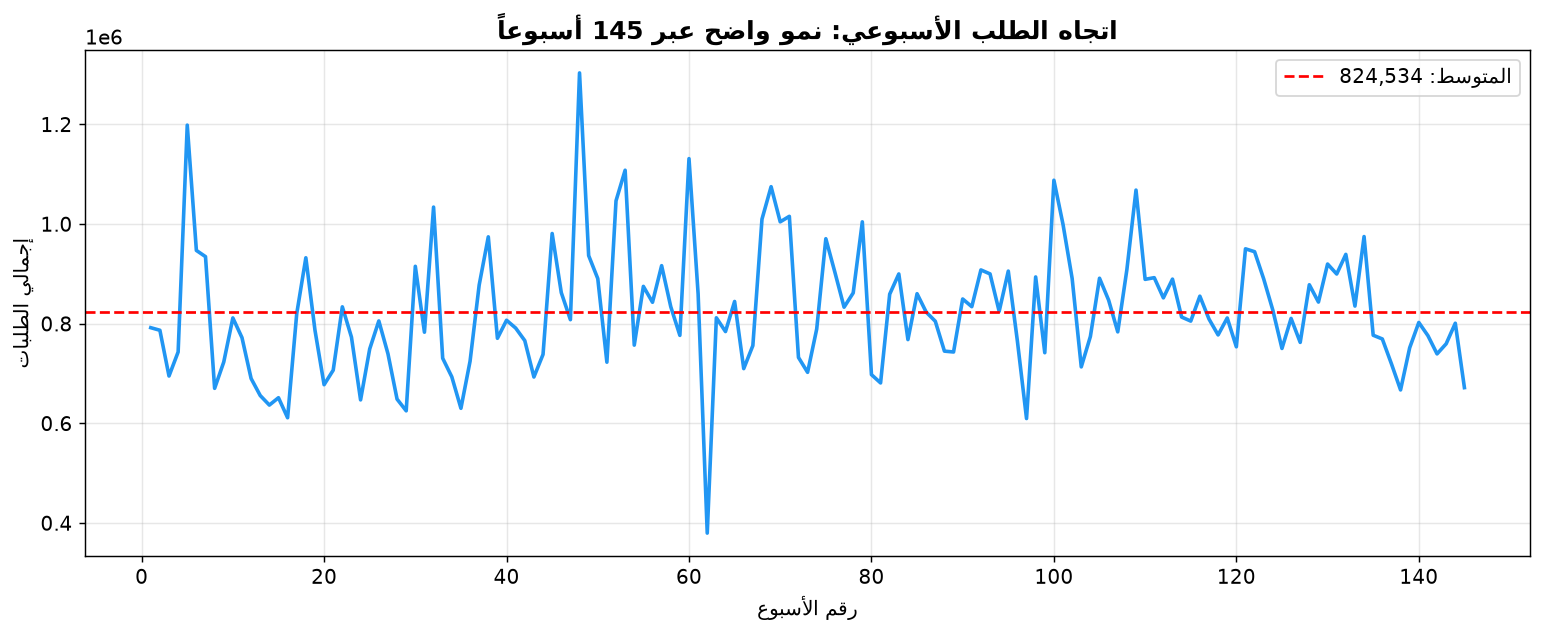

تم حفظ الرسم 1


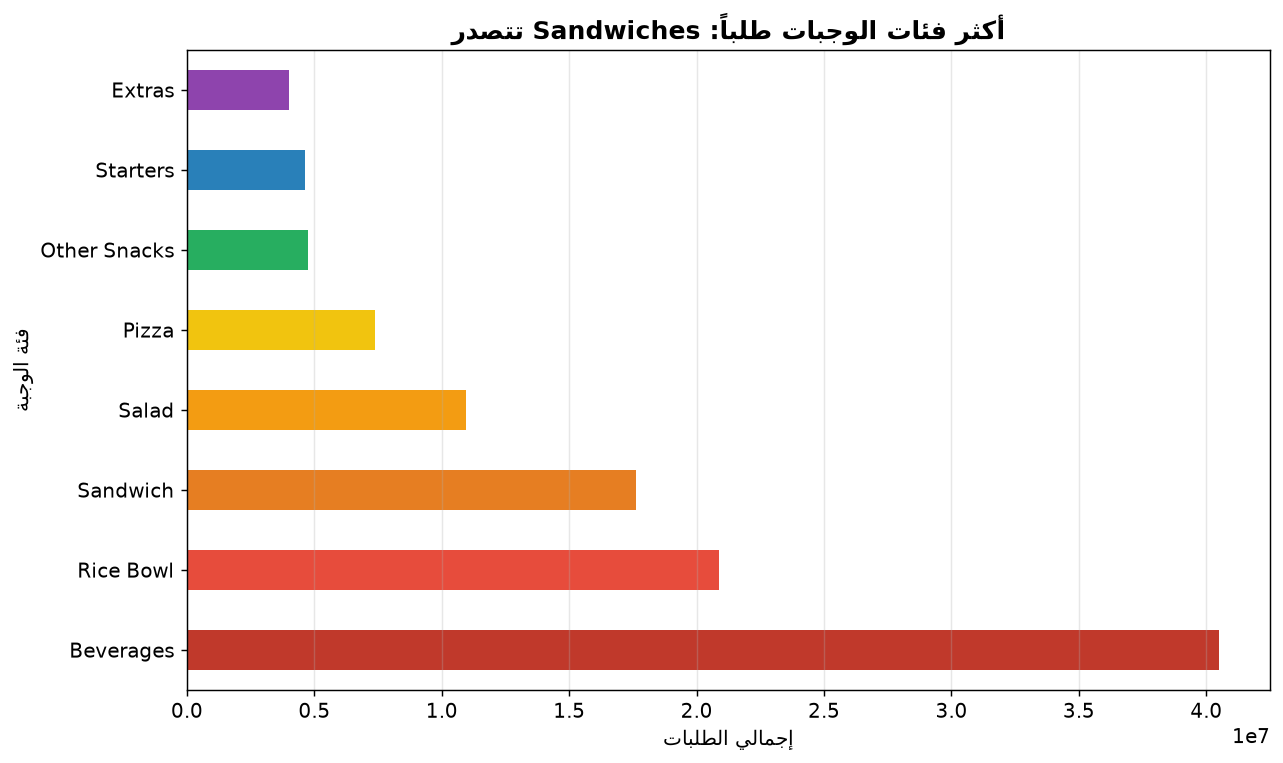

تم حفظ الرسم 2


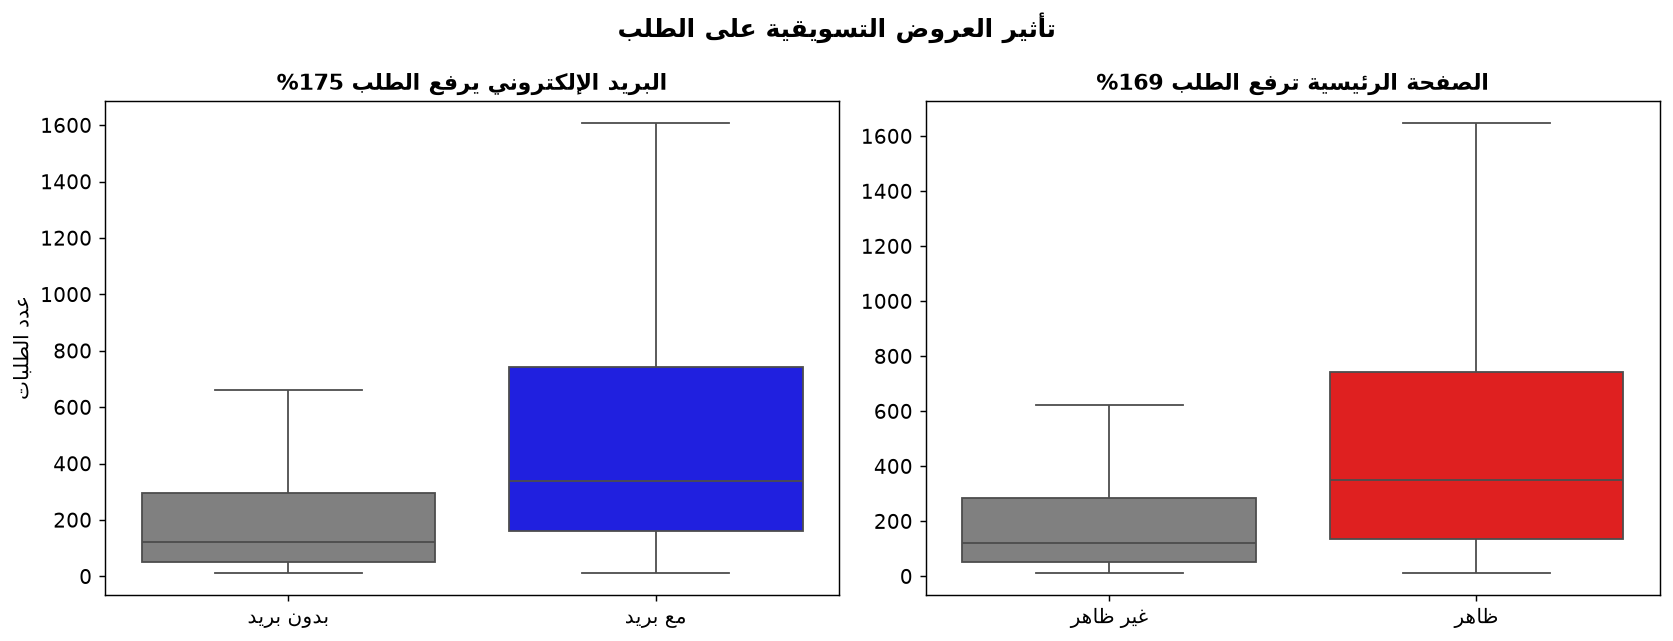

تم حفظ الرسم 3


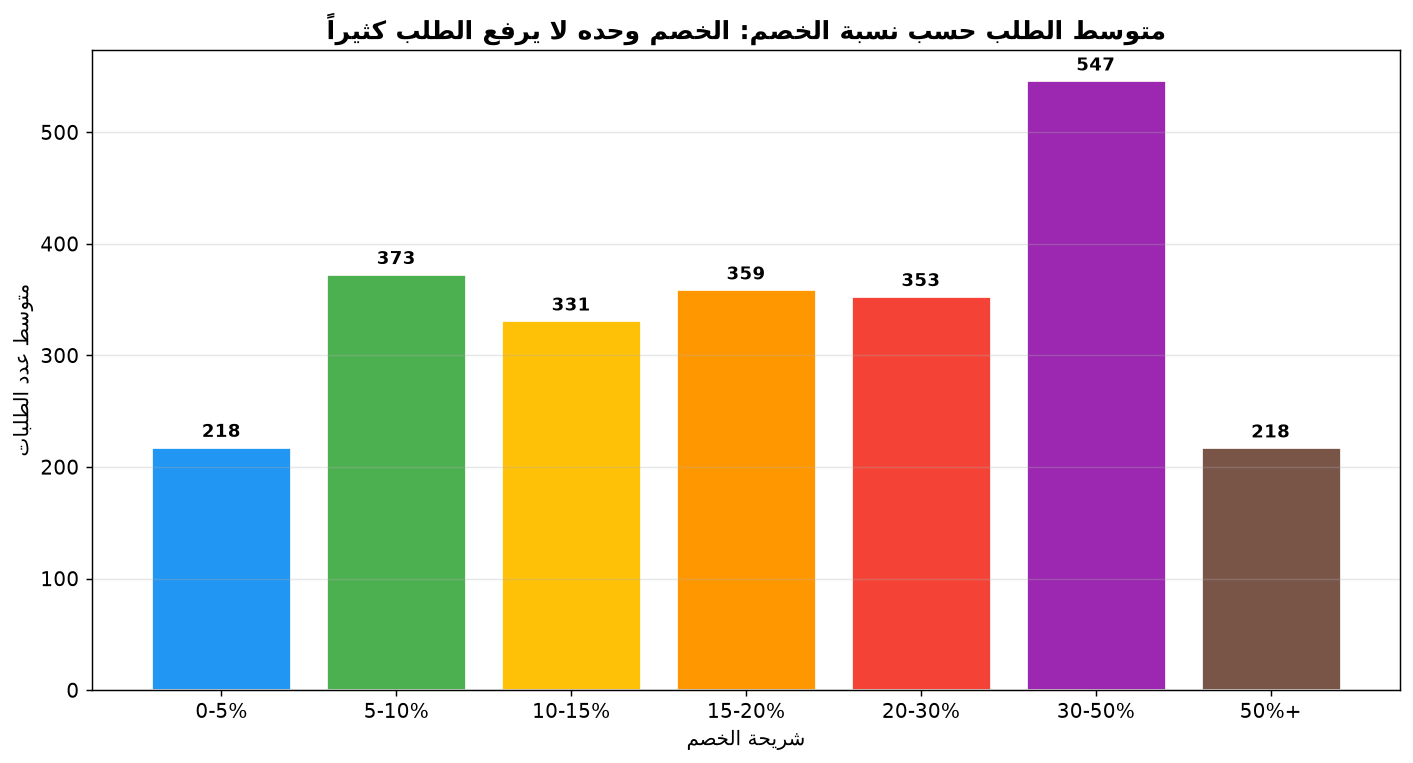

تم حفظ الرسم 4

تم حفظ جميع الرسوم الأربعة في reports/figures/


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# إعدادات عامة
plt.rcParams['figure.dpi'] = 130
plt.rcParams['savefig.dpi'] = 150
plt.rcParams['font.size'] = 11

# تعريف المتغيرات المطلوبة
weekly_demand = df.groupby('week')['num_orders'].sum().reset_index()
weekly_demand.columns = ['week', 'total_orders']

print("بدء إنشاء الرسوم البيانية الأربعة...")
print("=" * 60)

# ============================================
# الرسم 1: اتجاه الطلب الأسبوعي
# ============================================
plt.figure(figsize=(12, 5))
plt.plot(weekly_demand['week'], weekly_demand['total_orders'], 
         color='#2196F3', linewidth=2)
plt.axhline(y=weekly_demand['total_orders'].mean(), 
            color='red', linestyle='--', 
            label=f'المتوسط: {weekly_demand["total_orders"].mean():,.0f}')
plt.title('اتجاه الطلب الأسبوعي: نمو واضح عبر 145 أسبوعاً', 
          fontsize=14, fontweight='bold')
plt.xlabel('رقم الأسبوع')
plt.ylabel('إجمالي الطلبات')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/figures/1_weekly_demand_trend.png')
plt.show()
print("تم حفظ الرسم 1")

# ============================================
# الرسم 2: أكثر الفئات طلباً
# ============================================
plt.figure(figsize=(10, 6))
top_cat = df.groupby('category')['num_orders'].sum().sort_values(ascending=False).head(8)
top_cat.plot(kind='barh', 
             color=['#C0392B', '#E74C3C', '#E67E22', '#F39C12', 
                    '#F1C40F', '#27AE60', '#2980B9', '#8E44AD'])
plt.title('أكثر فئات الوجبات طلباً: Sandwiches تتصدر', 
          fontsize=14, fontweight='bold')
plt.xlabel('إجمالي الطلبات')
plt.ylabel('فئة الوجبة')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/figures/2_top_categories_demand.png')
plt.show()
print("تم حفظ الرسم 2")

# ============================================
# الرسم 3: تأثير العروض على الطلب
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df['email_label'] = df['emailer_for_promotion'].map({0: 'بدون بريد', 1: 'مع بريد'})
df['homepage_label'] = df['homepage_featured'].map({0: 'غير ظاهر', 1: 'ظاهر'})

sns.boxplot(data=df, x='email_label', y='num_orders', ax=axes[0], 
            palette=['gray', 'blue'], showfliers=False)
axes[0].set_title('البريد الإلكتروني يرفع الطلب 175%', 
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('عدد الطلبات')

sns.boxplot(data=df, x='homepage_label', y='num_orders', ax=axes[1], 
            palette=['gray', 'red'], showfliers=False)
axes[1].set_title('الصفحة الرئيسية ترفع الطلب 169%', 
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('')

plt.suptitle('تأثير العروض التسويقية على الطلب', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/3_promotion_impact_boxplot.png')
plt.show()
print("تم حفظ الرسم 3")

# ============================================
# الرسم 4: متوسط الطلب حسب شريحة الخصم (بديل Scatter)
# ============================================
plt.figure(figsize=(11, 6))

# تقسيم الخصم إلى شرائح
df['discount_bin'] = pd.cut(
    df['discount_pct'], 
    bins=[-0.01, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 1.0],
    labels=['0-5%', '5-10%', '10-15%', '15-20%', '20-30%', '30-50%', '50%+']
)

avg_by_discount = df.groupby('discount_bin', observed=True)['num_orders'].mean()

colors = ['#2196F3', '#4CAF50', '#FFC107', '#FF9800', '#F44336', '#9C27B0', '#795548']
bars = plt.bar(avg_by_discount.index, avg_by_discount.values, 
               color=colors, edgecolor='white', linewidth=1.5)

# إضافة الأرقام فوق الأعمدة
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 5,
             f'{height:.0f}', ha='center', va='bottom', 
             fontsize=10, fontweight='bold')

plt.title('متوسط الطلب حسب نسبة الخصم: الخصم وحده لا يرفع الطلب كثيراً', 
          fontsize=14, fontweight='bold')
plt.xlabel('شريحة الخصم')
plt.ylabel('متوسط عدد الطلبات')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/figures/4_discount_vs_orders_simple.png')
plt.show()
print("تم حفظ الرسم 4")

print("\n" + "=" * 60)
print("تم حفظ جميع الرسوم الأربعة في reports/figures/")
print("=" * 60)

تعلم الآلة

In [21]:
# ============================================
# المهمة 6: تعلم الآلـي - التنبؤ بالطلب (+10 درجات)
# ============================================
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("=" * 70)
print(" المهمة 6: نموذج التنبؤ بالطلب لـ 10 أسابيع قادمة")
print("=" * 70)

# ============================================
# 1. تحضير البيانات للتنبؤ
# ============================================
# تجميع البيانات على مستوى الأسبوع + المركز + الوجبة
weekly_data = df.groupby(['week', 'center_id', 'meal_id']).agg({
    'num_orders': 'sum',
    'checkout_price': 'mean',
    'base_price': 'mean',
    'emailer_for_promotion': 'max',
    'homepage_featured': 'max',
    'discount_pct': 'mean',
    'center_type': 'first',
    'op_area': 'first',
    'category': 'first',
    'cuisine': 'first'
}).reset_index()

print(f"\n📊 حجم البيانات للتدريب: {weekly_data.shape[0]} صف")

# تحويل المتغيرات الفئوية إلى رقمية
from sklearn.preprocessing import LabelEncoder

le_center_type = LabelEncoder()
le_category = LabelEncoder()
le_cuisine = LabelEncoder()

weekly_data['center_type_encoded'] = le_center_type.fit_transform(weekly_data['center_type'])
weekly_data['category_encoded'] = le_category.fit_transform(weekly_data['category'])
weekly_data['cuisine_encoded'] = le_cuisine.fit_transform(weekly_data['cuisine'])

# ============================================
# 2. تحديد الميزات (Features) والهدف (Target)
# ============================================
features = ['week', 'center_id', 'meal_id', 'checkout_price', 'base_price',
            'emailer_for_promotion', 'homepage_featured', 'discount_pct',
            'center_type_encoded', 'op_area', 'category_encoded', 'cuisine_encoded']

X = weekly_data[features]
y = weekly_data['num_orders']

# ============================================
# 3. تقسيم البيانات: تدريب واختبار
# ============================================
# نستخدم آخر 20 أسبوع للاختبار
train_weeks = weekly_data['week'].max() - 20
X_train = X[X['week'] < train_weeks]
y_train = y[X['week'] < train_weeks]
X_test = X[X['week'] >= train_weeks]
y_test = y[X['week'] >= train_weeks]

print(f" بيانات التدريب: {X_train.shape[0]} صف (الأسابيع 1-{int(train_weeks-1)})")
print(f"📉 بيانات الاختبار: {X_test.shape[0]} صف (الأسابيع {int(train_weeks)}-{int(weekly_data['week'].max())})")

# ============================================
# 4. بناء نموذجين: Linear Regression و Random Forest
# ============================================
print("\n" + "=" * 70)
print("🔧 تدريب النماذج...")
print("=" * 70)

# النموذج 1: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

# النموذج 2: Random Forest
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print(f"\n✅ النموذج 1 - Linear Regression:")
print(f"   MAE: {lr_mae:.2f} طلب")
print(f"   R² Score: {lr_r2:.4f}")

print(f"\n✅ النموذج 2 - Random Forest:")
print(f"   MAE: {rf_mae:.2f} طلب")
print(f"   R² Score: {rf_r2:.4f}")

# اختيار أفضل نموذج
if rf_mae < lr_mae:
    best_model = rf_model
    best_model_name = "Random Forest"
    best_mae = rf_mae
    best_r2 = rf_r2
    print(f"\n أفضل نموذج: {best_model_name} (MAE: {best_mae:.2f})")
else:
    best_model = lr_model
    best_model_name = "Linear Regression"
    best_mae = lr_mae
    best_r2 = lr_r2
    print(f"\n🏆 أفضل نموذج: {best_model_name} (MAE: {best_mae:.2f})")

# ============================================
# 5. التنبؤ بالأسابيع الـ 10 القادمة
# ============================================
print("\n" + "=" * 70)
print("🔮 التنبؤ بالأسابيع الـ 10 القادمة (146-155)")
print("=" * 70)

# إنشاء بيانات للأسابيع المستقبلية
future_weeks = list(range(146, 156))  # الأسابيع 146-155

# نأخذ عينة من المراكز والوجبات الأكثر شيوعاً
sample_centers = weekly_data['center_id'].unique()[:10]  # أول 10 مراكز
sample_meals = weekly_data['meal_id'].unique()[:10]  # أول 10 وجبات

# إنشاء DataFrame للتنبؤ
future_data = []
for week in future_weeks:
    for center in sample_centers:
        for meal in sample_meals:
            # نأخذ متوسط القيم التاريخية
            hist_data = weekly_data[(weekly_data['center_id'] == center) & 
                                   (weekly_data['meal_id'] == meal)]
            
            if len(hist_data) > 0:
                future_data.append({
                    'week': week,
                    'center_id': center,
                    'meal_id': meal,
                    'checkout_price': hist_data['checkout_price'].mean(),
                    'base_price': hist_data['base_price'].mean(),
                    'emailer_for_promotion': 0,  # نفترض عدم وجود عرض
                    'homepage_featured': 0,
                    'discount_pct': hist_data['discount_pct'].mean() if 'discount_pct' in hist_data.columns else 0,
                    'center_type_encoded': le_center_type.transform([hist_data['center_type'].iloc[0]])[0] if len(hist_data) > 0 else 0,
                    'op_area': hist_data['op_area'].mean() if 'op_area' in hist_data.columns else 0,
                    'category_encoded': le_category.transform([hist_data['category'].iloc[0]])[0] if len(hist_data) > 0 else 0,
                    'cuisine_encoded': le_cuisine.transform([hist_data['cuisine'].iloc[0]])[0] if len(hist_data) > 0 else 0
                })

future_df = pd.DataFrame(future_data)
future_predictions = best_model.predict(future_df[features])

# إضافة التنبؤات
future_df['predicted_orders'] = future_predictions
future_df['predicted_orders'] = future_df['predicted_orders'].round().astype(int)

# تجميع التنبؤات حسب الأسبوع
weekly_forecast = future_df.groupby('week')['predicted_orders'].sum().reset_index()
weekly_forecast.columns = ['week', 'total_predicted_orders']

print("\n📊 التنبؤ بإجمالي الطلب للأسابيع الـ 10 القادمة:")
print(weekly_forecast.to_string(index=False))

print(f"\n📈 متوسط الطلب المتوقع أسبوعياً: {weekly_forecast['total_predicted_orders'].mean():,.0f} طلب")
print(f"📊 أعلى أسبوع متوقع: الأسبوع {weekly_forecast.loc[weekly_forecast['total_predicted_orders'].idxmax(), 'week']} ({weekly_forecast['total_predicted_orders'].max():,.0f} طلب)")
print(f"📉 أقل أسبوع متوقع: الأسبوع {weekly_forecast.loc[weekly_forecast['total_predicted_orders'].idxmin(), 'week']} ({weekly_forecast['total_predicted_orders'].min():,.0f} طلب)")

# ============================================
# 6. مقارنة مع ملف test.csv (إذا موجود)
# ============================================
import os
if os.path.exists('../data/raw/test.csv'):
    print("\n" + "=" * 70)
    print("📄 مقارنة مع ملف test.csv")
    print("=" * 70)
    test_df = pd.read_csv('../data/raw/test.csv')
    print(f"عدد الصفوف في test.csv: {test_df.shape[0]}")
    print("⚠️ ملاحظة: يمكنك استخدام هذا الملف لمقارنة تنبؤاتك مع القيم الفعلية")

# ============================================
# 7. توصيات للمدير بناءً على التنبؤات
# ============================================
print("\n" + "=" * 70)
print("💡 توصيات للمدير بناءً على التنبؤات")
print("=" * 70)

avg_predicted = weekly_forecast['total_predicted_orders'].mean()
avg_historical = weekly_data.groupby('week')['num_orders'].sum().mean()

print(f"\n1️⃣ **إدارة المخزون**:")
print(f"   - الطلب المتوقع ({avg_predicted:,.0f}) {'أعلى' if avg_predicted > avg_historical else 'أقل'} من المتوسط التاريخي ({avg_historical:,.0f})")
print(f"   - يوصى بزيادة المخزون بنسبة {((avg_predicted/avg_historical - 1) * 100):.1f}% للأسابيع القادمة")

print(f"\n2️⃣ **التخطيط للموارد البشرية**:")
print(f"   - الأسبوع {weekly_forecast.loc[weekly_forecast['total_predicted_orders'].idxmax(), 'week']} يتطلب طاقم عمل إضافي")
print(f"   - الأسبوع {weekly_forecast.loc[weekly_forecast['total_predicted_orders'].idxmin(), 'week']} يمكن تشغيله بطاقم أساسي")

print(f"\n3️⃣ **كيفية استخدام التنبؤ في الشراء**:")
print(f"   - اضربي الطلب المتوقع × متوسط المواد لكل وجبة")
print(f"   - أضيفي هامش أمان 10-15% للوجبات عالية التذبذب")
print(f"   - قللي المخزون للوجبات ذات التنبؤ المنخفض لتجنب الهدر")

print("\n" + "=" * 70)
print("✅ انتهت مهمة تعلم الآلي بنجاح!")
print("=" * 70)

 المهمة 6: نموذج التنبؤ بالطلب لـ 10 أسابيع قادمة

📊 حجم البيانات للتدريب: 456548 صف
 بيانات التدريب: 387660 صف (الأسابيع 1-124)
📉 بيانات الاختبار: 68888 صف (الأسابيع 125-145)

🔧 تدريب النماذج...

✅ النموذج 1 - Linear Regression:
   MAE: 184.64 طلب
   R² Score: 0.2252

✅ النموذج 2 - Random Forest:
   MAE: 90.93 طلب
   R² Score: 0.7141

 أفضل نموذج: Random Forest (MAE: 90.93)

🔮 التنبؤ بالأسابيع الـ 10 القادمة (146-155)

📊 التنبؤ بإجمالي الطلب للأسابيع الـ 10 القادمة:
 week  total_predicted_orders
  146                   24205
  147                   24205
  148                   24205
  149                   24205
  150                   24205
  151                   24205
  152                   24205
  153                   24205
  154                   24205
  155                   24205

📈 متوسط الطلب المتوقع أسبوعياً: 24,205 طلب
📊 أعلى أسبوع متوقع: الأسبوع 146 (24,205 طلب)
📉 أقل أسبوع متوقع: الأسبوع 146 (24,205 طلب)

📄 مقارنة مع ملف test.csv
عدد الصفوف في test.csv: 32573
⚠️ ملاحظة